In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.lines import Line2D
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import os
import pandas as pd
import datetime as dt
import matplotlib.colors as mcolors
import json
import csv
from itertools import product
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, Normalize


In [2]:
class data():
    def __init__(self,folder,period,start_date, end_date,BG,BG_ds,footprint='spec001_mr',correlation='with',g_err=2,i_err=3, only=None):
        self.folder = folder
        self.period = period
        self.start_date=start_date
        self.end_date=end_date
        self.correlation=correlation
        self.color=''
        self.BG=BG
        self.BG_ds=BG_ds
        self.g_err=g_err
        self.i_err=i_err
        self.footprint=footprint
        if only==None:
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/{self.i_err}ppm_insitu_meas_err/'
        elif only=='gosat':
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.g_err}ppm_gosat_meas_err/'
        elif only=='insitu':
            self.path = f'{self.folder}/2x2/{self.correlation}_correlation/footprint_{self.footprint}/{self.i_err}ppm_insitu_meas_err/'


    # Class attributes
    def read_fluxes(self):
        self.fluxes=xr.open_dataset(f'{self.path}/{self.period}_{self.BG_ds}_bg.nc')
        self.fluxes['time']=pd.to_datetime(self.fluxes.time)
        self.fluxes=self.fluxes.where((self.fluxes.time>=pd.to_datetime(self.start_date-dt.timedelta(days=6)))&(self.fluxes.time<=pd.to_datetime(self.end_date)),drop=True)
    def read_gosat(self):
        self.gosat=xr.open_dataset(f'{self.path}/gosat_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.gosat=self.gosat.where((self.gosat.release_time>=pd.to_datetime(self.start_date))&(self.gosat.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.gosat=self.gosat.where((self.gosat.release_lat>analy_region_lat[0])&(self.gosat.release_lat<analy_region_lat[1])&(self.gosat.release_lon>analy_region_lon[0])&(self.gosat.release_lon<analy_region_lon[1]),drop=True)

    def read_insitu(self):
        self.insitu=xr.open_dataset(f'{self.path}/insitu_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.insitu=self.insitu.where((self.insitu.release_time>=pd.to_datetime(self.start_date))&(self.insitu.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.insitu=self.insitu.where((self.insitu.release_lat>analy_region_lat[0])&(self.insitu.release_lat<analy_region_lat[1])&(self.insitu.release_lon>analy_region_lon[0])&(self.insitu.release_lon<analy_region_lon[1]),drop=True)
    def read_tccon(self):
        self.tccon=xr.open_dataset(f'{self.path}/TCCON_data_2x2_{self.period}_{self.BG_ds}_bg.nc')
        self.tccon=self.tccon.where((self.tccon.release_time>=pd.to_datetime(self.start_date))&(self.tccon.release_time<=pd.to_datetime(self.end_date)),drop=True)
        self.tccon=self.tccon.where((self.tccon.release_lat>analy_region_lat[0])&(self.tccon.release_lat<analy_region_lat[1])&(self.tccon.release_lon>analy_region_lon[0])&(self.tccon.release_lon<analy_region_lon[1]),drop=True)

    def read_data(self):
        self.read_fluxes()
        self.read_gosat()
        self.read_insitu()
        self.read_tccon()

In [3]:
def plot_inner_2x2_region_fluxes(datasets_dir,labels,parameters,parameters_uncertainty, colors,markers, title, start_date, end_date,spath):
    ''' plot time series of prior, posterior and TM5-4DVar reference fluxes for all grid cells in inner domain
    Args:
        data_dir:   path to inversion directory
        ref_flux_dir: TM5-4DVar flux directory
        gosat_err_val: gosat measurement error value
        meas_err_val: insitu measurement error value
        corr_str: sting indicating if with or withour correlation
        color_sel: color for posterior flux
        bg_str: TM5-4DVar dataset used for the background, defaults to RemoTeC_2.4.0+IS
    Returns: nothing, saves plot'''
    data={}
    for k,dir in enumerate(datasets_dir):
        print(dir)
        data[labels[k]]=xr.open_dataset(dir).sel(latitude=slice(20,48), longitude=slice(-123,-73))

    title_str=f'Total 2x2 flux, {title}'
    lat_lon_list=[(lat, lon) for lat in data[labels[0]].latitude.values for lon in data[labels[0]].longitude.values]
    # sort by latitude descending, longitude ascending
    lat_lon_list=sorted(lat_lon_list, key=lambda x: (-x[0], x[1]))
    # plot overview
    fig, ax=plt.subplots(data[labels[0]].latitude.size, data[labels[0]].longitude.size, figsize=(data[labels[0]].longitude.size*6, data[labels[0]].latitude.size*6), sharey=True)
    ax=ax.flatten()
    # marker size
    ms=2
    for i in range(0, len(lat_lon_list)):
        lat_sel, lon_sel =lat_lon_list[i]
        # select region
        for k in range(len(labels)):
            if 'GCP' in labels[k]:
                s=labels[k][-1]
                data_sel=data[labels[k]].sel(ensemble_member=int(s))
                data_sel=data_sel.sel(latitude=lat_sel, longitude=lon_sel)
                name=''
                for r in data_sel.ensemble_member_name.values[0]:
                    name+=r
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=name)
            else:
                data_sel=data[labels[k]].sel(latitude=lat_sel, longitude=lon_sel)
                ax[i].plot(data_sel.time, data_sel[parameters[k]], c=colors[k], marker=markers[k], markersize=ms, label=labels[k])
            if parameters_uncertainty[k]!=False:
                ax[i].fill_between(data_sel.time, data_sel[parameters[k]]-data_sel[parameters_uncertainty[k]], data_sel[parameters[k]]+data_sel[parameters_uncertainty[k]], 
                                color=colors[k], alpha=0.2)        
        ax[i].legend()
        ax[i].set_title(f'lat/lon: {lat_sel}/{lon_sel}')
        ax[i].set_xlim(start_date,end_date)
        #ax[i].set_xlim(dt.date(2010,1,1), dt.date(2010,12,31))
        ax[i].tick_params(labelleft=True)
        ax[i].set_ylim(-4e-7, 4e-7)
        # You can change the step of range() as you prefer (now, it selects each third month) 
        ax[i].xaxis.set_major_locator(mdates.MonthLocator(bymonth=range(1,12,3)))
        ax[i].xaxis.set_minor_locator(mdates.MonthLocator(bymonth=range(1,13,1)))
        ax[i].xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
        ax[i].grid(which='both', c='grey', alpha=0.5)
    fig.suptitle(title_str)
    fig.tight_layout(rect=[0, 0., 1, 0.98])

    fig.savefig(spath)
    print(f'saved to: {spath}')
    plt.close()
    return

In [4]:
def plot_map(data,label,ax,vmin=-0.6,vmax=0.6):
    plot=data.plot(ax=ax, cmap='RdBu_r', vmin=vmin, vmax=vmax, cbar_kwargs={'location':'bottom','shrink':0.85, 'label':label})
    plot.colorbar.ax.xaxis.label.set_size(12)
    plot.colorbar.ax.tick_params(labelsize=12)
        
    ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='g')
    ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='g')
    ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='g')
    
    ax.set_xlabel('longitude')
    ax.set_ylabel('latitude')
    # Add coastlines
    ax.coastlines(linewidth=0.5, alpha=0.3)
    # Add U.S. state borders
    ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
    gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {'size': 10}
    gl.ylabel_style = {'size': 10}
    ax.grid(c='lightgrey')
    ax.set_xlim(-134,-62) 
    ax.set_ylim(12,56)
    ax.tick_params(labelsize=20)
    ax.set_title('')

In [5]:
analy_region_lat=[20,48]
analy_region_lon=[-126,-70]

# four_times_four 
res=2
n_regions=[2,3] #lat, lon
lat_dist=round((analy_region_lat[1]-analy_region_lat[0])/n_regions[0]/res)*res
lon_dist=round((analy_region_lon[1]-analy_region_lon[0])/n_regions[1]/res)*res
#define region edges
regions_lat=[]
for i in range(n_regions[0]+1): #lat
    if i == n_regions[0]:
        regions_lat.append(analy_region_lat[1])
    else:
        regions_lat.append(analy_region_lat[0]+i*lat_dist)
regions_lon=[]
for i in range(n_regions[1]+1): #lat
    if i == n_regions[1]:
        regions_lon.append(analy_region_lon[1])
    else:
        regions_lon.append(analy_region_lon[0]+i*lon_dist)

In [6]:
print(regions_lat)
print(regions_lon)

[20, 34, 48]
[-126, -108, -90, -70]


In [7]:
period='20201001-20220331'
analysis_start_date, analysis_end_date =dt.date(2021,1,1), dt.date(2021,12,31)  
start_date, end_date =dt.date(2019,10,1), dt.date(2023,3,31)  
color=['red','blue','yellow','purple','gray','orange', 'pink']
savefig='figures_2/CAMS_vs_TM5/'

In [8]:
BG_TM5='TM5'
BG_TM5_ds='RemoTeC_2.4.1+IS-land_ocean_bc'

TM5_last_pos= data('inversions_new/TM5_correlations/',period,start_date, end_date,BG_TM5,BG_TM5_ds,correlation='with',g_err=2,i_err=3)
TM5_last_pos.read_data()

TM5_inversion_region =data('inversions_new/TM5_last_pos_region/',period,start_date, end_date,BG_TM5,BG_TM5_ds,correlation='with',g_err=2,i_err=3)
TM5_inversion_region.read_data()

In [9]:
TM54DVar_posterior_flux=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_RemoTeC_2.4.1+IS_cut_weekly.nc')
TM54DVar_posterior_flux=TM54DVar_posterior_flux.where((TM54DVar_posterior_flux.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(TM54DVar_posterior_flux.time<=pd.to_datetime(analysis_end_date)),drop=True)

prior=xr.open_dataset('/work/bb1170/RUN/b383736/data/Flexpart_2021/TM54DVar/TM54DVar_fluxes/flux_2x2_prior_cut_weekly.nc')
prior=prior.where((prior.time>=pd.to_datetime(analysis_start_date-dt.timedelta(days=6)))&(prior.time<=pd.to_datetime(analysis_end_date)),drop=True)

<>:6: SyntaxWarning: invalid escape sequence '\m'
<>:6: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_3740386/3250273445.py:6: SyntaxWarning: invalid escape sequence '\m'
  plot.colorbar.set_label('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]', size=18)


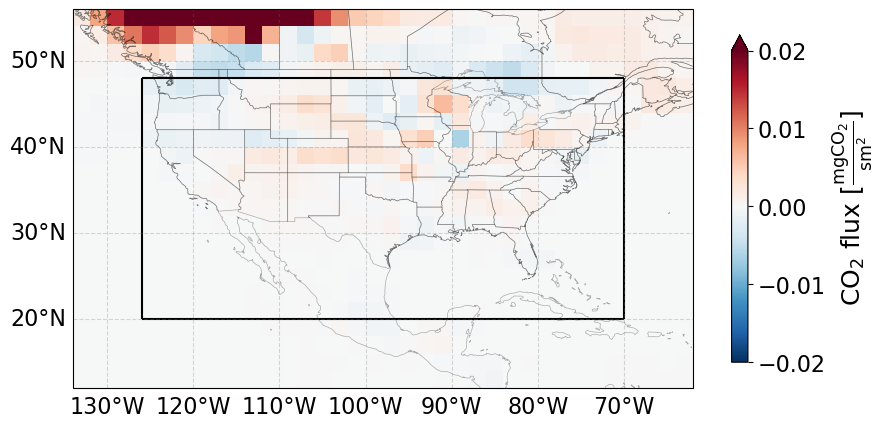

In [14]:
fig,ax=plt.subplots(figsize=(10,5), subplot_kw={'projection': ccrs.PlateCarree()})
vmin=0.02
data=(TM5_last_pos.fluxes.TM5_posterior_flux-TM5_inversion_region.fluxes.TM5_posterior_flux).mean('time')*1e6
plot=data.plot(ax=ax, cmap='RdBu_r', vmin=-vmin, vmax=vmin,rasterized=True, cbar_kwargs={'location':'right','shrink':0.85})
plot.colorbar.ax.tick_params(labelsize=16)
plot.colorbar.set_label('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]', size=18)


ax.hlines(analy_region_lat[0],analy_region_lon[0],analy_region_lon[1],color='black')
ax.hlines(analy_region_lat[1],analy_region_lon[0],analy_region_lon[1],color='black')
ax.vlines(analy_region_lon[0],analy_region_lat[0],analy_region_lat[1],color='black')
ax.vlines(analy_region_lon[1],analy_region_lat[0],analy_region_lat[1],color='black')

ax.set_xlabel('longitude')
ax.set_ylabel('latitude')
# Add coastlines
ax.coastlines(linewidth=0.5, alpha=0.3)
# Add U.S. state borders
ax.add_feature(cfeature.STATES, edgecolor='black', linewidth=0.5,alpha=0.3)
gl = ax.gridlines(draw_labels=True,color='gray', alpha=0.3, linestyle='--')
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 16}
gl.ylabel_style = {'size': 16}
ax.grid(c='lightgrey')
ax.set_xlim(-134,-62) 
ax.set_ylim(12,56)
ax.tick_params(labelsize=20)
ax.set_title('')
ax.set_aspect(1)
plt.savefig(f'{savefig}/map_difference_background_position.pdf')
plt.show()


In [11]:
temp_last_pos=TM5_last_pos.fluxes.where(((TM5_last_pos.fluxes.latitude>= analy_region_lat[0]) &(TM5_last_pos.fluxes.latitude<analy_region_lat[1])),drop=True)
temp_last_pos=temp_last_pos.where(((temp_last_pos.longitude>= analy_region_lon[0]) &(temp_last_pos.longitude<analy_region_lon[1])),drop=True)
temp_inversion_region=TM5_inversion_region.fluxes.where(((TM5_inversion_region.fluxes.latitude>= analy_region_lat[0]) &(TM5_inversion_region.fluxes.latitude<analy_region_lat[1])),drop=True)
temp_inversion_region=temp_inversion_region.where(((temp_inversion_region.longitude>= analy_region_lon[0]) &(temp_inversion_region.longitude<analy_region_lon[1])),drop=True)
        

In [19]:
print('absolute difference')
print('max: '+str(np.max((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux).values)*1e6))
print('min: '+ str(np.min((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux).values)*1e6))
print('mean: '+ str(np.mean((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux).values)*1e6))
print('std: '+ str(np.std((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux).values)*1e6))
print('relativ difference:')
print('max: '+str(np.max((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux)/temp_last_pos.TM5_posterior_flux).values))
print('min: '+ str(np.min((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux)/temp_last_pos.TM5_posterior_flux).values))
print('mean: '+ str(np.mean((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux)/temp_last_pos.TM5_posterior_flux).values))
print('std: '+ str(np.std((temp_last_pos.TM5_posterior_flux-temp_inversion_region.TM5_posterior_flux)/temp_last_pos.TM5_posterior_flux).values))


absolute difference
max: 0.032127103508960364
min: -0.06039859649217874
mean: 7.852527226817793e-05
std: 0.0028361893523674428
relativ difference:
max: 396.04668628457085
min: -322.253017839903
mean: -0.00043158687849998605
std: 3.020438769280169


<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_206793/277425802.py:31: SyntaxWarning: invalid escape sequence '\m'
  axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')


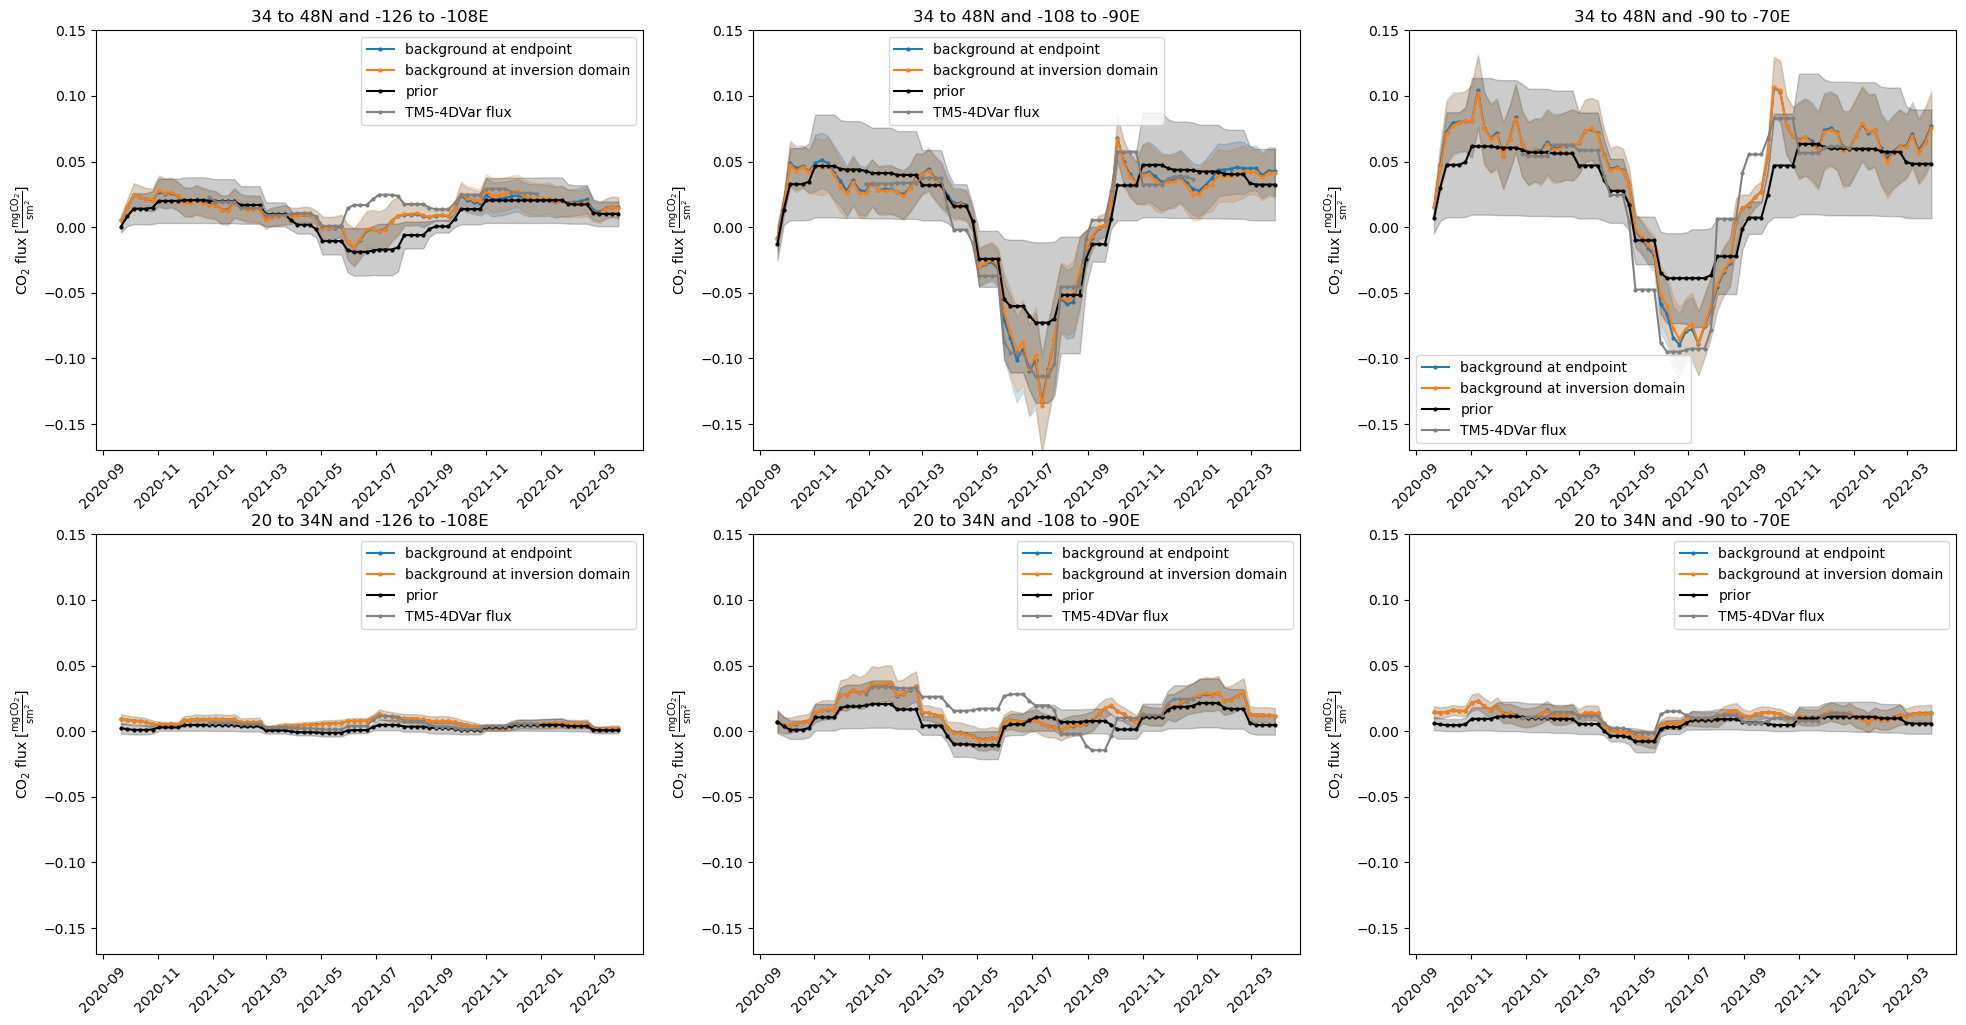

In [26]:
fig,axs=plt.subplots(2,3,figsize=(24,12))
min_max=[-0.17,0.17]
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
label_set=['background at endpoint','background at inversion domain' ]                           # ['NEE ampl.','NEE 2*ampl.','NEE 0.5*ampl.','NEE scaled', 'no diurnal']
datasets= [TM5_last_pos, TM5_inversion_region ]                                  # [nee_amplitude,nee2_amplitude,nee05_amplitude,scaled, no_diurnal]
for i in range(n_regions[0]): #lat
    for j in range(n_regions[1]): #lon
        k=0
        for k,data in enumerate(datasets):
            temp=data.fluxes
            temp=temp.where(((temp.latitude>= regions_lat[-i-2]) &(temp.latitude<regions_lat[-i-1])),drop=True)
            temp=temp.where(((temp.longitude>= regions_lon[j]) &(temp.longitude<regions_lon[j+1])),drop=True)
            temp=temp.mean(['latitude','longitude'])
            temp['TM5_prior_flux']=temp.TM5_prior_flux*1e6
            temp['prior_uncertainty']=temp.prior_uncertainty*1e6
            temp['TM5_posterior_flux']=temp.TM5_posterior_flux*1e6
            temp['TM5_posterior_std']=temp.TM5_posterior_std*1e6
            axs[i,j].plot(temp.time, temp.TM5_posterior_flux, c=default_colors[k], marker='o', markersize=2, label=f'{label_set[k]}')
            axs[i,j].fill_between(temp.time, temp.TM5_posterior_flux-temp.TM5_posterior_std, temp.TM5_posterior_flux+temp.TM5_posterior_std, color=default_colors[k], alpha=0.2) 
            k+=1

        temp3=TM54DVar_posterior_flux.where(((TM54DVar_posterior_flux.latitude>= regions_lat[-i-2]) &(TM54DVar_posterior_flux.latitude<regions_lat[-i-1])),drop=True)
        temp3=temp3.where(((temp3.longitude>= regions_lon[j]) &(temp3.longitude<regions_lon[j+1])),drop=True)
        temp3=temp3.mean(['latitude','longitude'])
        temp3['total_flux']=temp3.total_flux*1e6

        axs[i,j].plot(temp.time, temp.TM5_prior_flux, c='black', marker='o', markersize=2, label='prior')
        axs[i,j].fill_between(temp.time, temp.TM5_prior_flux-temp.prior_uncertainty, temp.TM5_prior_flux+temp.prior_uncertainty, color='black', alpha=0.2)  
        axs[i,j].plot(temp3.time, temp3.total_flux, c='grey', marker='o', markersize=2, label='TM5-4DVar flux')

        axs[i,j].set_ylabel('$\mathrm{CO_2}$ flux [$\mathrm{\\frac{mgCO_2}{s m^2}}$]')
        axs[i,j].legend()
        axs[i,j].set_ylim(-0.17,0.15)
        axs[i,j].tick_params(axis='x', labelrotation=45)
        axs[i,j].set_title(f"{regions_lat[-i-2]} to {regions_lat[-i-1]}N and {regions_lon[j]} to {regions_lon[j+1]}E")
        #axs[i,j].tight_layout()
plt.savefig(f'{savefig}/regional_fluxes_diff_background_positions.png',bbox_inches='tight')#,transparent=True)
plt.show()
#plt.close()